---
title: Inferential statistics
subtitle: Using sample data to draw conclusions about a population
format:
    typst:
        echo: false

execute:
  enabled: false
editor:
    render-on-save: true
progress: true
incremental: true
slide-level: 3
jupyter: python3
---

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.stats import t
from numpy.random import normal
from scipy.stats import norm

np.set_printoptions(linewidth=105)

mpl.rc_file('/home/njs/miniconda3/lib/python3.11/site-packages/matplotlib/mpl-data/matplotlibrc')

custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme('talk', style='white', rc=custom_params)

### Inferential statistics this week and next 

1.  Estimation
2.  Significance tests
3.  Linear models
4.  Multiple testing


### Estimating population parameters

### Weddell seal dive durations

![](Images/weddell_seals.png){width=300}

- Marine biologists want to estimate the mean dive duration of weddell seals
- Estimated population size in Antarctica ~200,000 seals
- They cannot measure every dive of every seal in Antarctica
- They therefore measured dive duration in a sample of 10 seals from the Ross sea by attaching satellite telemetric tags



| Dive duration (mins) |
| --: |
| 49.5 |
| 46.3 |
| 50.2 |
| 54.6 |
| 45.8 |
| 45.8 |
| 54.9 |
| 50.8 |
| 44.7 |
| 49.7 |
| $\bar{x}=$ **49.2** |

The sample mean is denoted $\bar{x}$

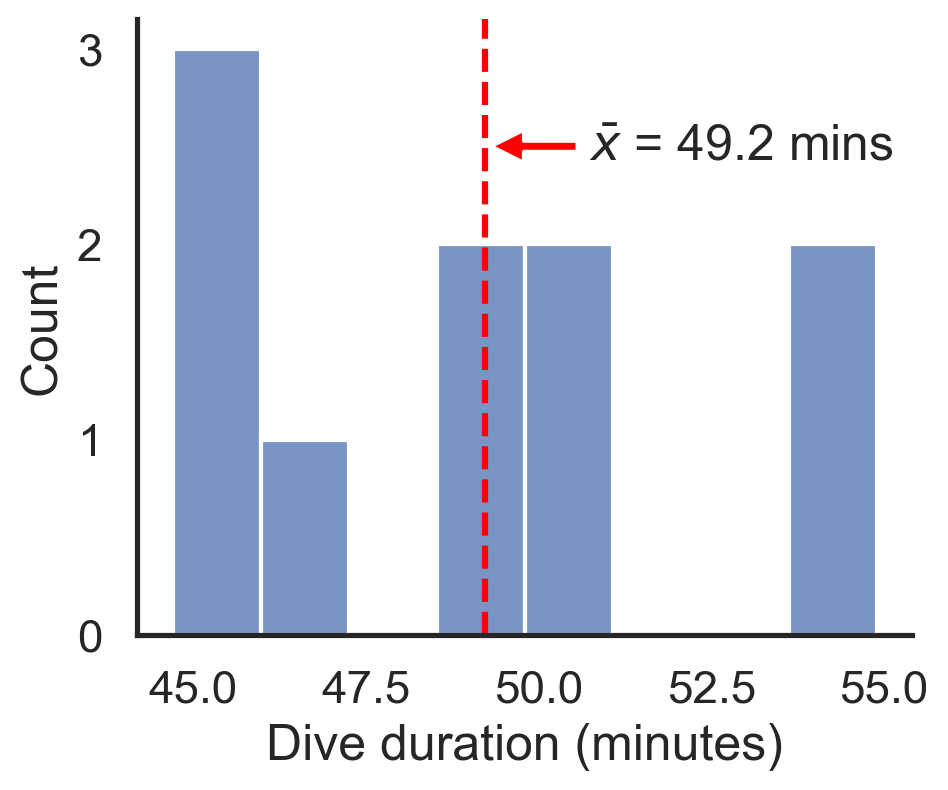

In [2]:
#| output: false
#| fig-align: center

fig, ax = plt.subplots(figsize=(5, 4))
dives = pd.read_csv('../Datasets/weddell_seal_dives.csv')

xbar = dives['dive_duration_min'].mean()

ax = sns.histplot(dives['dive_duration_min'], bins=8, ax=ax)
ax.set_xlabel('Dive duration (minutes)')
ax.axvline(xbar, color='red', linestyle='--')
ax.annotate(fr'$\bar{{x}}$ = {xbar:.1f} mins', xy=(xbar, 2.5), xytext=(xbar + 1.5, 2.5),
            arrowprops=dict(facecolor='red', shrink=0.05), va='center');
fig.savefig('Images/fig1.png', bbox_inches='tight')

### Distribution of dive durations

![](Images/fig1.png)

- The mean dive duration of this sample is 49.2 minutes
- But we would like to know the overall mean duration of all Weddell seal dives
- This is called the **population mean**, usually denoted $\mu$
 

- But we can never know the population mean because we can't measure every single dive
- The best we can do is estimate it


- A **point estimate** of the population mean is usually denoted $\hat{\mu}$
- The best point estimate of the population mean is the sample mean:

    $$\hat{\mu} = \bar{x} = 49.2\, \text{mins}$$

### A point estimate is not enough information

But what if the marine biologists sampled a different set of 10 weddell seal dives

Sample 1  | Sample 2  | Sample 3 |
--: | --: | --: |
49.5 | 44.7 | 45.7 |
46.3 | 49.3 | 43.4 |
50.2 | 48.2 | 47.3 |
54.6 | 37.4 | 39.9 |
45.8 | 38.4 | 44.3 |
45.8 | 44.2 | 44.3 |
54.9 | 41.9 | 46.5 |
50.8 | 48.6 | 43.2 |
44.7 | 42.5 | 45.0 |
49.7 | 54.3 | 44.0 |
$\bar{x}_1=$ **49.2** | $\bar{x}_2=$ **45.0** | $\bar{x}_3=$ **44.4** |

Three different point estimates


- We have just one point estimate of the population mean ($\hat{\mu} =$ 49.2 minutes)

- But there is some uncertainty in its value because only 10 dives were recorded

    $$\hat{\mu} = 49.2 \pm \text{uncertainty}$$

- How much uncertainty is there? For example, is it:
    - 49.2 $\pm$ 10 mins (around 39 to 59 mins)?
    - 49.2 $\pm$ 1 mins (around 48 to 50 mins)?

- We must quantify the uncertainty in dive durations

### The uncertainty in the estimate of a population mean

There are two common methods of reporting the uncertainty in the estimate of a population mean

1. Standard error of the mean (SEM)
    - Good when your sample size is more than about 20
    - But is inaccurate when the sample size is less than about 20
2. 95% confidence interval
    - Good for all sample sizes
    - SEM is used to calculate 95% CI

### The standard error of the mean

The formula for the standard error of the mean is 

$$
\text{SEM} = \frac{\text{Standard deviation of the sample}}{\text{Square root of number of observations}} = \frac{s}{\sqrt{n}}
$$

Where does this formula come from?


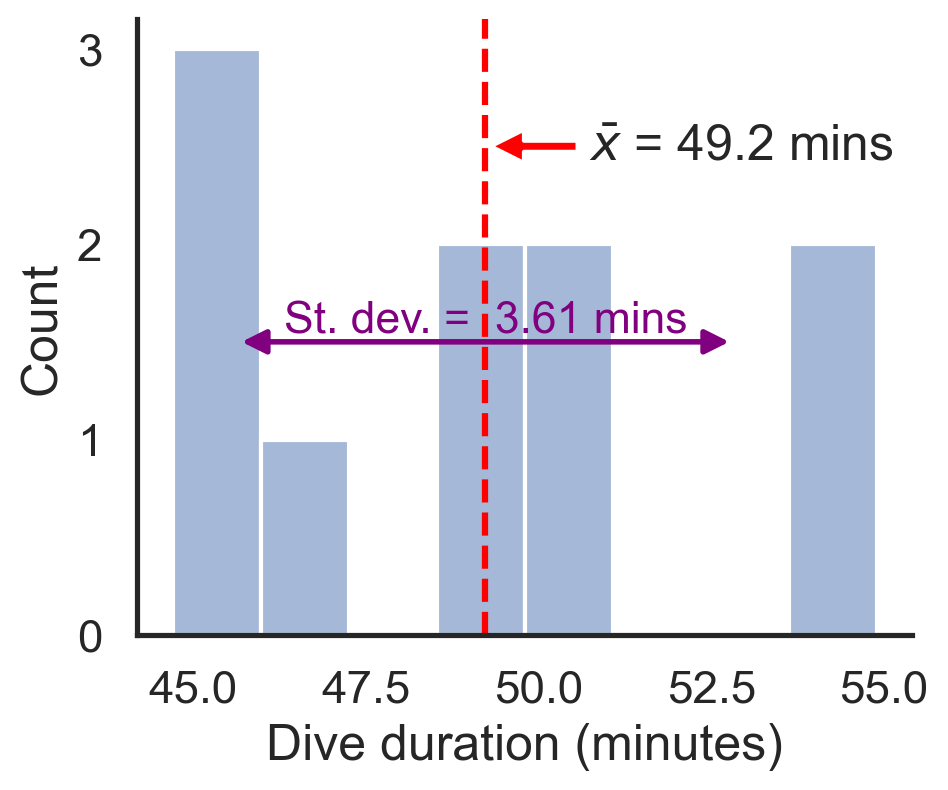

In [3]:
#| fig-align: center

fig, ax = plt.subplots(figsize=(5, 4))

xbar = dives['dive_duration_min'].mean()
s = dives['dive_duration_min'].std()

ax = sns.histplot(dives['dive_duration_min'], bins=8, alpha=0.5, ax=ax)
ax.set_xlabel('Dive duration (minutes)')
ax.axvline(xbar, color='red', linestyle='--')
ax.annotate(fr'$\bar{{x}}$ = {xbar:.1f} mins', xy=(xbar, 2.5), xytext=(xbar + 1.5, 2.5),
            arrowprops=dict(facecolor='red', shrink=0.05), va='center');
# ax.annotate(
#     '',
#     xy=(xbar + s, 1.5),
#     xytext=(xbar - s, 1.5),
#     arrowprops=dict(arrowstyle='|-|', lw=2, color='purple'),
# )
ax.annotate(
    '',
    xy=(xbar + s, 1.5),
    xytext=(xbar - s, 1.5),
    arrowprops=dict(arrowstyle='<|-|>', lw=2, color='purple'),
)

ax.text(xbar, 1.5, 'St. dev. =  3.61 mins', ha='center', va='bottom', fontsize=16, color='purple')
# ax.text(xbar+1.1*s, 1.8, '+1 st.dev.', ha='right', va='bottom', fontsize=16, color='purple')
# ax.set_title(f'Standard deviation = {s:.2f} mins', fontdict={'size': 16, 'color': 'purple'});
plt.savefig('Images/fig5.png', bbox_inches='tight')

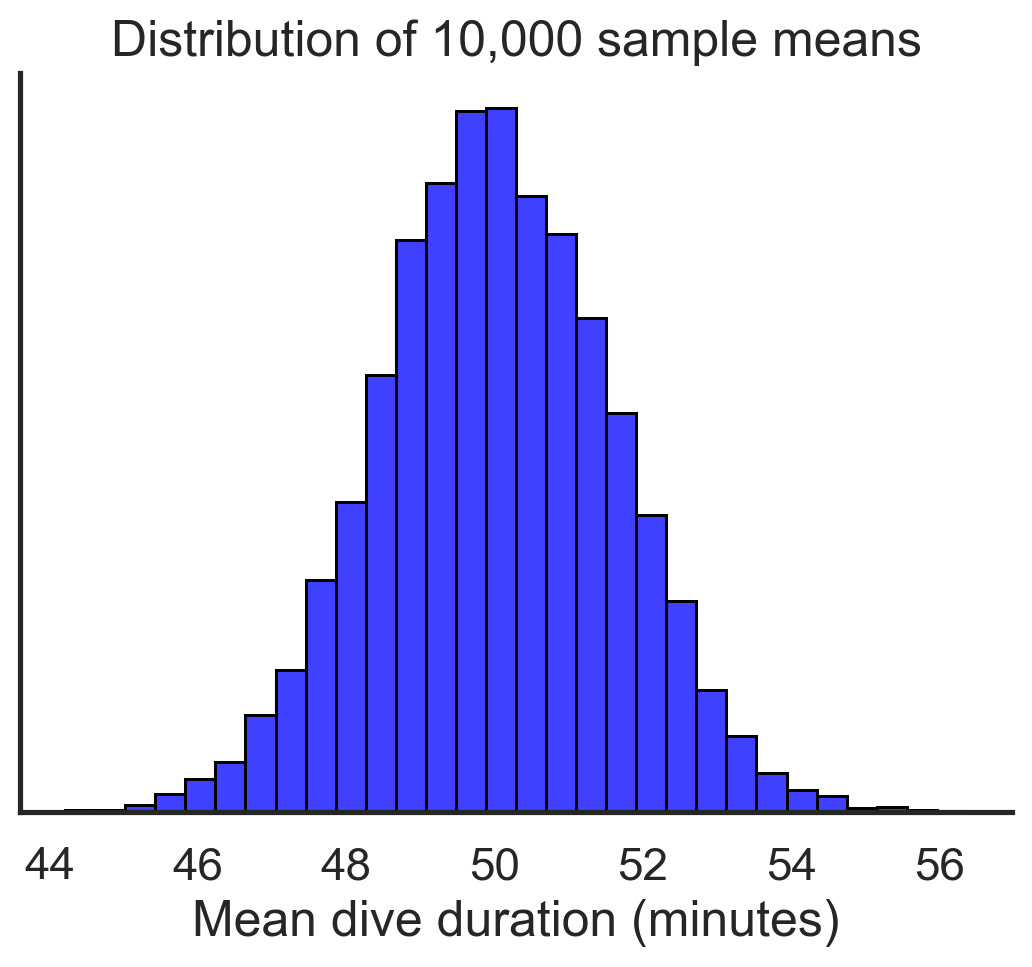

In [4]:
#| output: false

mu = 50
samples = normal(loc=mu, scale=5, size=(10000, 10))

xbars = samples.mean(axis=1)

ax = sns.histplot(xbars, bins=30, color='blue', edgecolor='black')
ax.set_xlabel('Mean dive duration (minutes)')
ax.set_title('Distribution of 10,000 sample means');
ax.set_ylabel('')
ax.set_yticks([])
plt.savefig('Images/fig2.png', bbox_inches='tight')

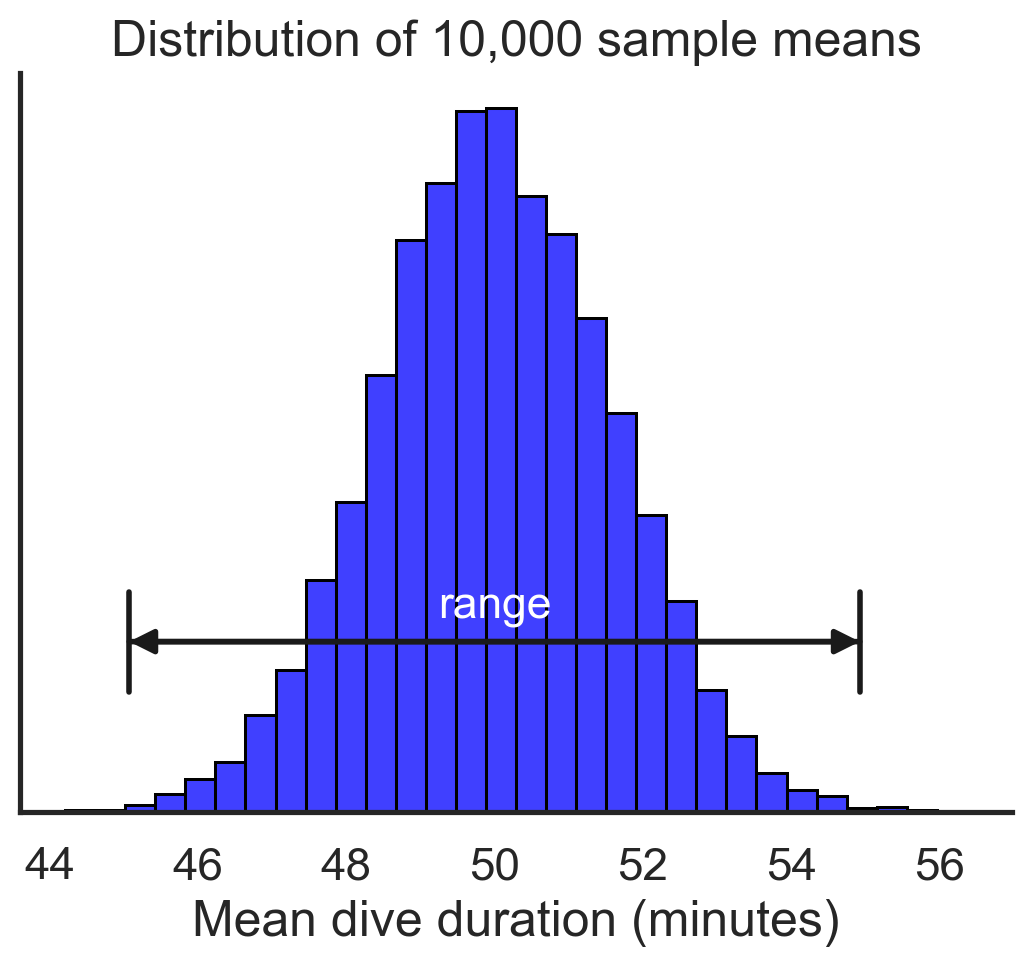

In [5]:
#| output: false

ax = sns.histplot(xbars, bins=30, color='blue', edgecolor='black')
ax.set_xlabel('Mean dive duration (minutes)')
ax.set_title('Distribution of 10,000 sample means');
ax.set_ylabel('')
ax.set_yticks([])

ax.annotate( '', xy=(45, 250), xytext=(55, 250), arrowprops=dict(arrowstyle='|-|', lw=2, color='k'), )
ax.annotate( '', xy=(45, 250), xytext=(55, 250), arrowprops=dict(arrowstyle='<|-|>', lw=2, color='k'), )
ax.text(50, 270, 'range', ha='center', va='bottom', fontsize=16, color='white');
plt.savefig('Images/fig3.png', bbox_inches='tight')

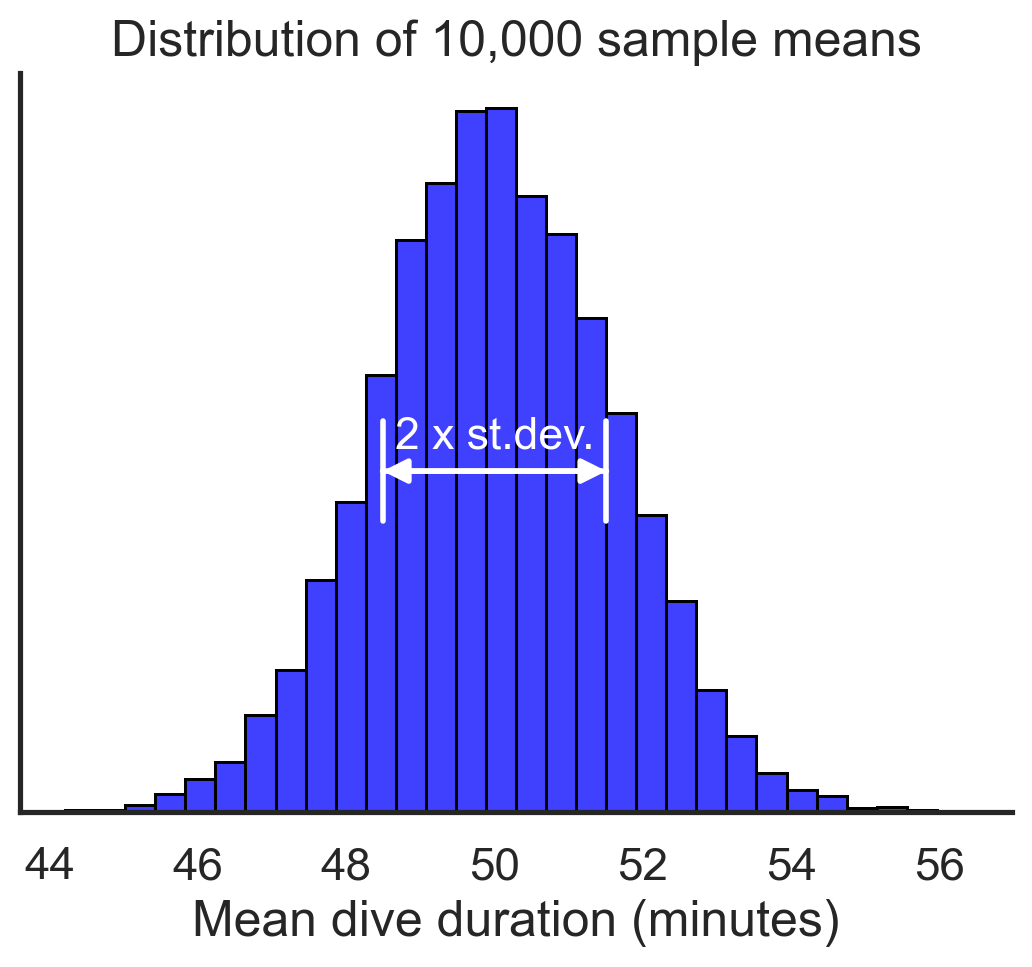

In [6]:
#| output: false

ax = sns.histplot(xbars, bins=30, color='blue', edgecolor='black')
ax.set_xlabel('Mean dive duration (minutes)')
ax.set_title('Distribution of 10,000 sample means');
ax.set_ylabel('')
ax.set_yticks([])

s = xbars.std()
ax.annotate( '', xy=(50 + s, 500), xytext=(50 - s, 500), arrowprops=dict(arrowstyle='|-|', lw=2, color='white'), )
ax.annotate( '', xy=(50 + s, 500), xytext=(50 - s, 500), arrowprops=dict(arrowstyle='<|-|>', lw=2, color='white'), )
ax.text(50, 520, '2 x st.dev.', ha='center', va='bottom', fontsize=16, color='white')

plt.savefig('Images/fig4.png', bbox_inches='tight')

### The sampling distribution {auto-animate=true}

- Say you had 10,000 samples, each of 10 dive durations
- Each sample has a mean. These will differ between samples
- The distribution of these 10,000 means is called a sampling distribution

![](Images/fig3.png){fig-align="center" width=400}

- So samples of 10 dive durations have means roughly in the range 45 to 55 minutes
- That's a range of about ± 5 minutes
- The width of the sampling distribution tells us the uncertainty in an estimate of the population mean 

- The mean of the sample measured by the marine biologists will lie somewhere in this sampling distribution
- So the uncertainty in the population mean estimate of 49.2 minutes is about ± 5 minutes

![](Images/fig4.png){fig-align="center" width=400}

- Actually we don't use the **range** of the sampling distribution, instead we use its **standard deviation**
- The standard deviation of the sampling distribution is called the **standard error of the mean**

It turns out, and you can prove this mathematically, that SEM is related to:

1. the variability of all dive durations (the population standard deviation, $\sigma$) and 
2. the sample size, $n$

$$
\text{SEM} = \frac{\text{Standard deviation of the population}}{\text{Square root of number of observations}} = \frac{\sigma}{\sqrt{n}}
$$


- However, we don't know the standard deviation of the population, $\sigma$
- But we do know the standard deviation of the sample, $s$
- $s$ is an estimate of $\sigma$
- So replace $\sigma$ with $s$

$$
\text{SEM} = \frac{\text{Standard deviation of the sample}}{\text{Square root of number of observations}} = \frac{s}{\sqrt{n}}
$$


### Calculating SEM

![](Images/fig5.png)

| Dive duration (mins) |
| --: |
| 49.5 |
| 46.3 |
| 50.2 |
| 54.6 |
| 45.8 |
| 45.8 |
| 54.9 |
| 50.8 |
| 44.7 |
| 49.7 |
| $\bar{x}=$ **49.2** |


In [ ]:
#| echo: true
#| output-location: fragment

dives = pd.read_csv('../Datasets/weddell_seal_dives.csv')

n = dives['dive_duration_min'].count()
xbar = dives['dive_duration_min'].mean()
s = dives['dive_duration_min'].std()

# Either
sem = s/np.sqrt(n)
# or
sem = dives['dive_duration_min'].sem()

print(f'n:    {n}')
print(f'xbar: {xbar:.2f} mins')
print(f's:    {s:.2f} mins')
print(f'SEM:  {sem:.2f} mins')

n:    10
xbar: 49.23 mins
s:    3.61 mins
SEM:  1.14 mins


### The 95% confidence interval

To calculate SEM we replaced the standard deviation of the population $\sigma$ (which we don't know) with the standard deviation of the sample $s$ (which we do know)

$$
\text{SEM} = \frac{\text{Standard deviation of the sample}}{\text{Square root of number of observations}} = \frac{s}{\sqrt{n}}
$$

- This assumes that $s$ is a good estimate of $\sigma$ 
- But when the sample size is small, $s$ is *not* a good estimate of $\sigma$

- The sample standard deviation $s$ underestimates the population standard deviation $\sigma$.

- And the underestimate gets worse at smaller sample sizes


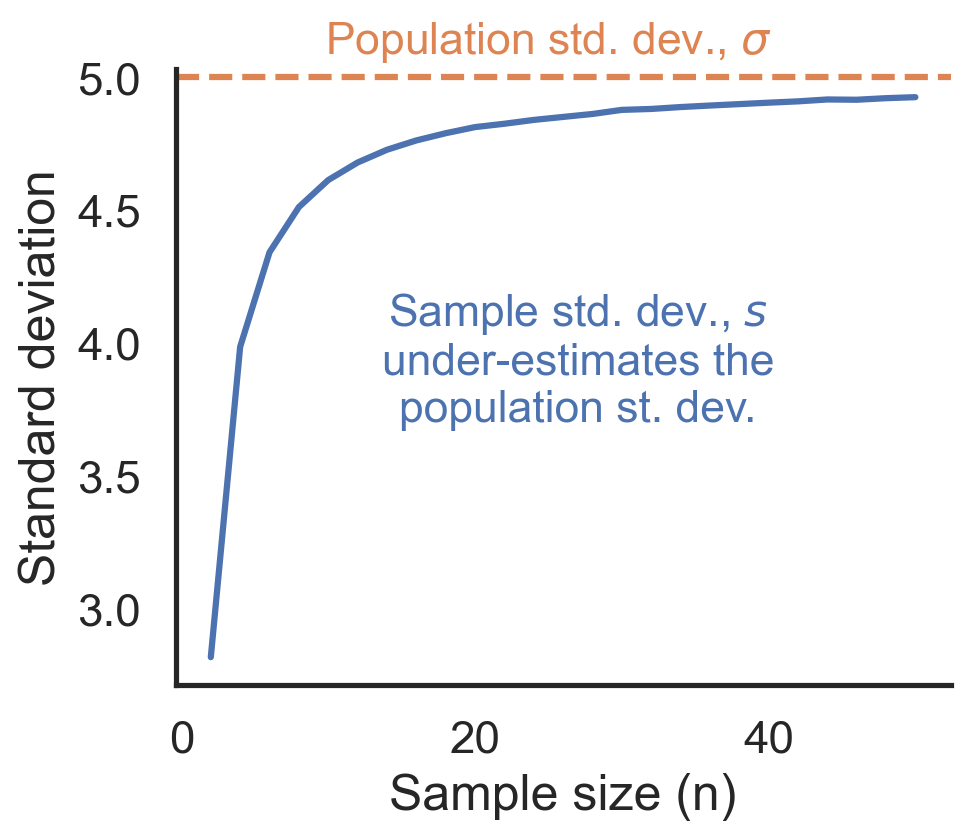

In [8]:
#| fig-align: center

df = {'n':[], 'mean':[], 'low':[], 'high':[]}

for n in range(2, 51, 2):
    x = normal(50, 5, size=(100000, n))
    s = x.std(axis=1)
    sbar = s.mean()
    # slow = np.percentile(s, 2.5)
    # shigh = np.percentile(s, 97.5)
    df['n'].append(n)
    df['mean'].append(sbar)
    # df['low'].append(slow)
    # df['high'].append(shigh)

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(df['n'], df['mean'], color='C0')
ax.set_ylabel('Standard deviation')
ax.set_xlabel('Sample size (n)')
ax.axhline(y=5, color='C1', linestyle='--')
ax.text(25, 5.05, r'Population std. dev., $\sigma$', ha='center', va='bottom', fontsize=16, color='C1')
ax.text(27, 4.2, 'Sample std. dev., $s$\nunder-estimates the\npopulation st. dev.', ha='center', va='top', fontsize=16, color='C0');

::: {.fragment}
So for small sample sizes we have to include a correction factor called $t_{n-1}$
:::

$$\hat{\mu} = \bar{x}\pm t_{n-1}\times\text{SEM}$$

The factor $t_{n-1}$ is a correction factor for small sample sizes.

*n* | $t_{n-1}$
--: | --:
2 | 12.71
5 | 2.78
10 | 2.26
20 | 2.09
50 | 2.01
100 | 1.98
500+ | 1.96


#### A rule of thumb: 

For samples with more than 20 observations $t_{n-1}$ is about 2
 
$$\hat{\mu} = \bar{x}\pm 2\times\text{SEM}$$


The code to calculate $t_{n-1}$ is

In [9]:
#| echo: true
#| output-location: fragment

from scipy.stats import t

t_df = t.ppf(0.975, df=9)

print(f't_df = {t_df:.2f}')

t_df = 2.26


::: {.fragment}
`df` stands for "degrees of freedom". In this case it is one less than the sample size. 
:::


### The final estimate

![](Images/fig5.png)

From the sample we have

$$
\begin{align*}
n &= 10 \\
\bar{x} &= 49.2\, \text{mins} \\
\text{SEM} &= 1.14\, \text{mins} \\
t_9 &= 2.26
\end{align*}
$$

$$
\begin{align*}
\hat{\mu} &= \bar{x}\pm t_{n-1}\times\text{SEM} \\
\hat{\mu} &= 49.2 \pm 2.26 \times 1.14 \\
\hat{\mu} &= 49.2 \pm 2.6\, \text{mins} \\
\end{align*}
$$
In conclusion, mean dive durations are about 49 minutes with an uncertainty of plus/minus two and a half minutes.


### The 95% confidence interval

95% CI are often written as a range from the low bound to the high bound. 


- low bound  = $\bar{x} - t_{n-1}\times\text{SEM}$
- high bound = $\bar{x} + t_{n-1}\times\text{SEM}$

::: {.fragment}

In [10]:
#| echo: true
#| output-location: fragment

ci_low  = xbar - t_df * sem
ci_high = xbar + t_df * sem

print(f'95% CI: [{ci_low:.1f}, {ci_high:.1f}] mins')


95% CI: [46.6, 51.8] mins


:::

- The 95% CI of dive durations is [`{python} f'{ci_low:.1f}'`, `{python} f'{ci_high:.1f}'`] mins.

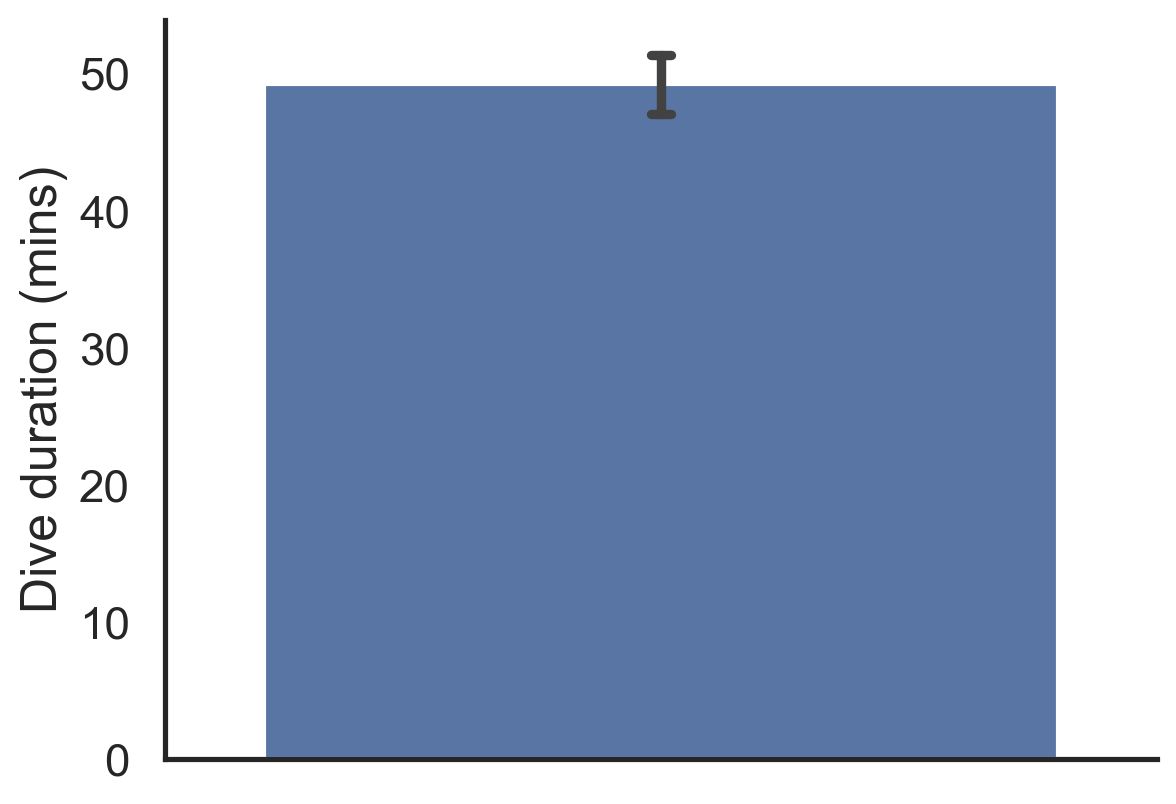

In [11]:
#| output: false
ax = sns.barplot(data=dives, y='dive_duration_min', capsize=.02);
ax.set_ylabel('Dive duration (mins)');
plt.savefig('Images/fig6.png', bbox_inches='tight')

### Visualising estimates {auto-animate=true}

- Uncertainty in point estimates are graphically represented as error bars
- Barplots are a common method

::: {.fragment}
```python
ax = sns.barplot(data=dives, y='dive_duration_min', capsize=.02);
ax.set_ylabel('Dive duration (mins)');
```
:::
::: {.fragment}
::: {data-id="fig6"}
![](Images/fig6.png){fig-align=center}
:::
:::

A bar plot creates a bar with the bottom at zero and the top at the point estimate. The errorbar extends from the low bound to the high bound of the 95% CI.

These plots are more useful when comparing things. Dive durations of different seal species, for example.

In [12]:
x1 = normal(90, 20, size=10)
x2 = normal(50, 10, size=10)
x3 = normal(30, 10, size=10)
x4 = normal(17, 5, size=10)
x5 = normal(12, 4, size=10)
dives_cmp = pd.concat([
    pd.DataFrame({'dive_duration_min': x1, 'group': 'Elephant seal'}),
    pd.DataFrame({'dive_duration_min': x2, 'group': 'Weddell seal'}),
    pd.DataFrame({'dive_duration_min': x3, 'group': 'Harbor seal'}),
    pd.DataFrame({'dive_duration_min': x4, 'group': 'Leopard seal'}),
    pd.DataFrame({'dive_duration_min': x5, 'group': 'Crabeater seal'})
], ignore_index=True)

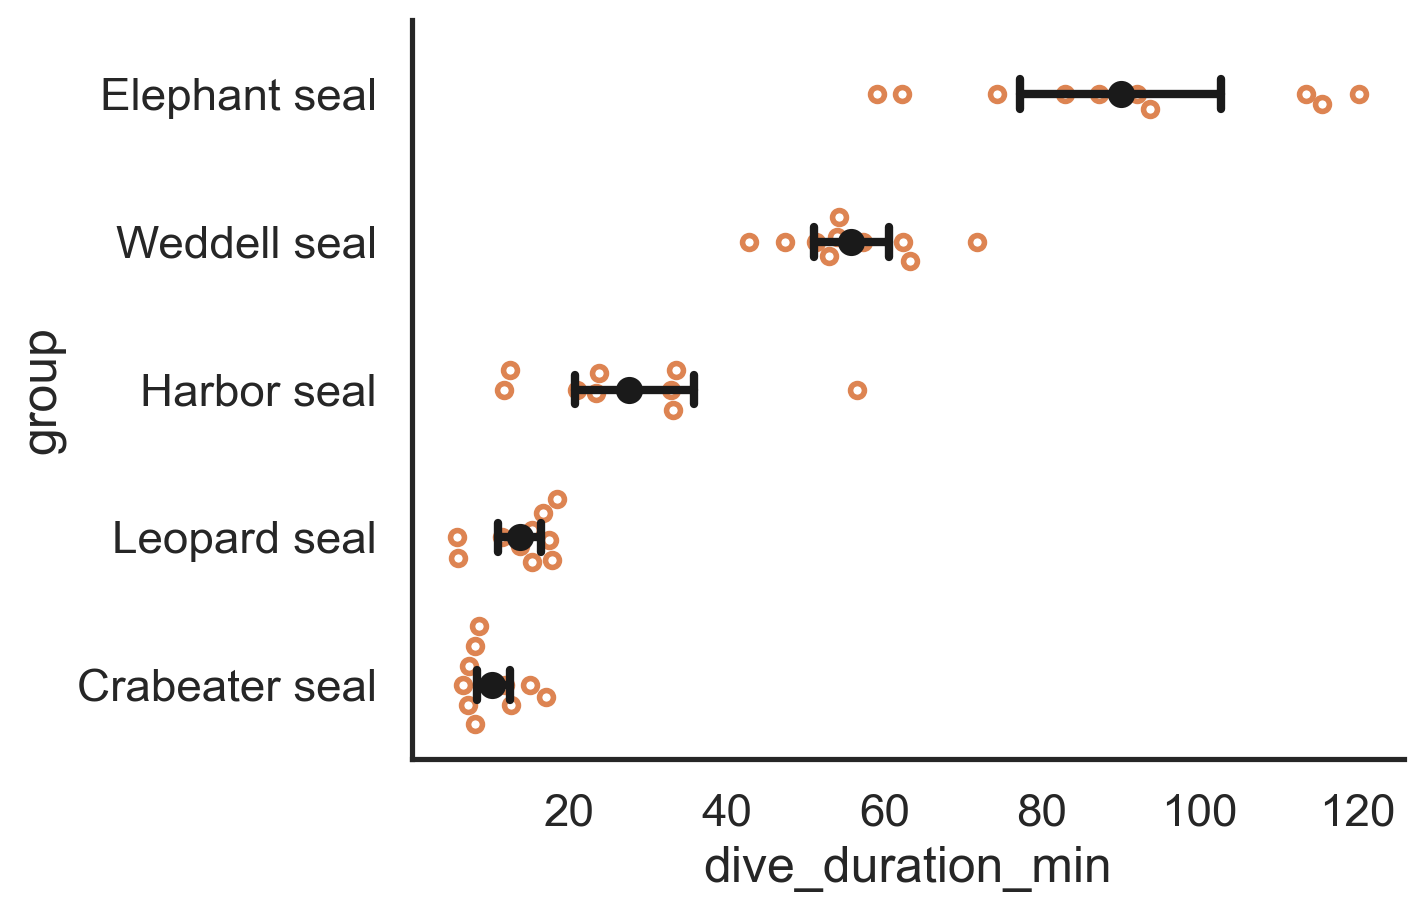

In [13]:
#| output: false

# make this here to get the xlimit extent, but do not show it until later

ax = sns.pointplot(data=dives_cmp, y='group', x='dive_duration_min', capsize=.2, color="k", linestyle="none", marker="o", linewidth=3)
sns.swarmplot(data=dives_cmp, y='group', x='dive_duration_min', marker='o', zorder=0, facecolor='w', edgecolor='C1', linewidth=2)
xlims = ax.get_xlim()

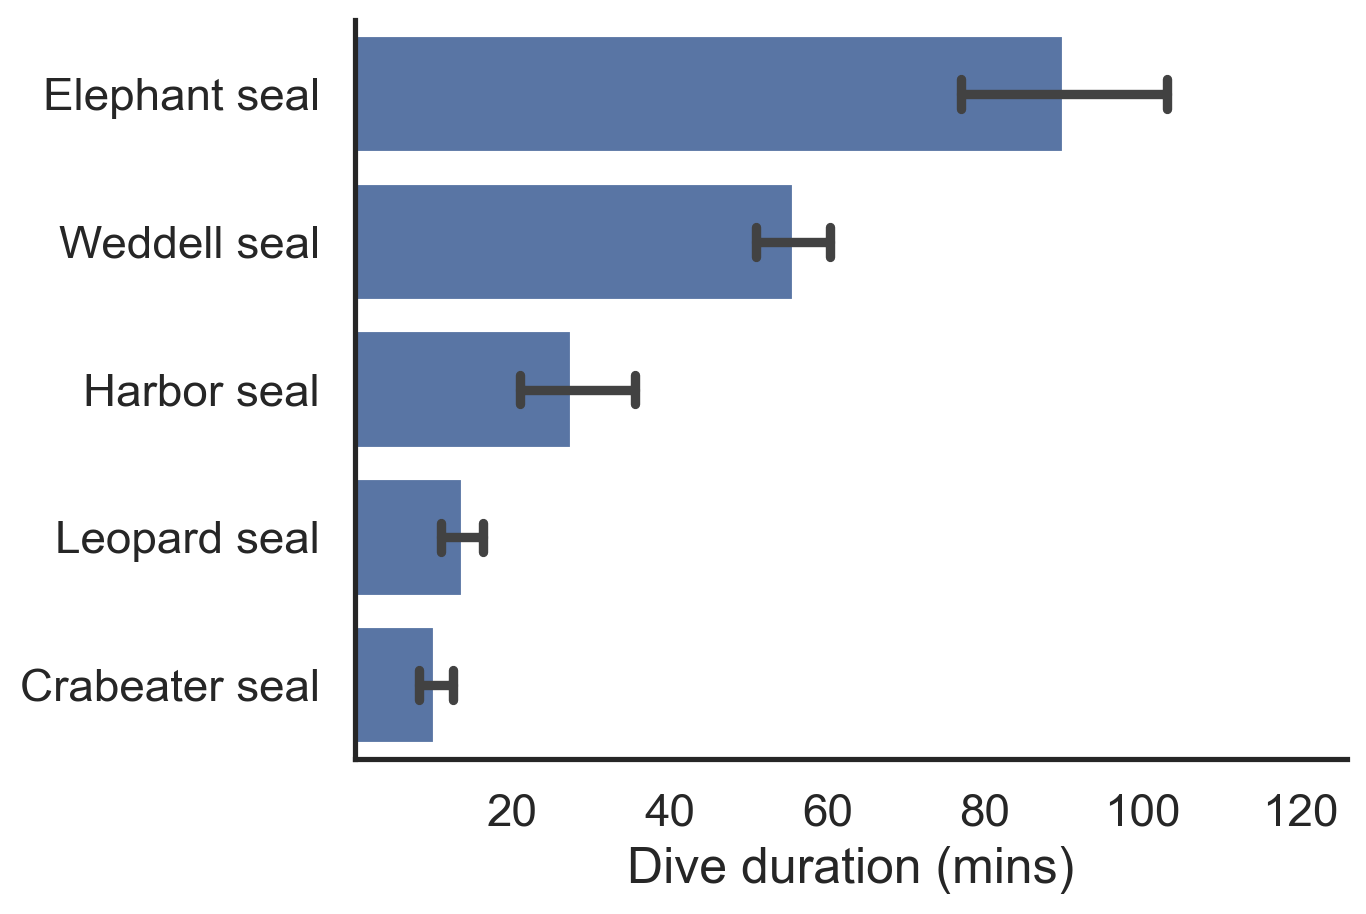

In [14]:
#| output: true
#| fig-align: center

ax = sns.barplot(data=dives_cmp, y='group', x='dive_duration_min', capsize=.2)
ax.set_xlim(*xlims)
ax.set_xlabel('Dive duration (mins)');
ax.set_ylabel('');


### Error bars in a point plot

A point plot just plots a circle at the point estimate. This gives a less cluttered figure than a bar plot.

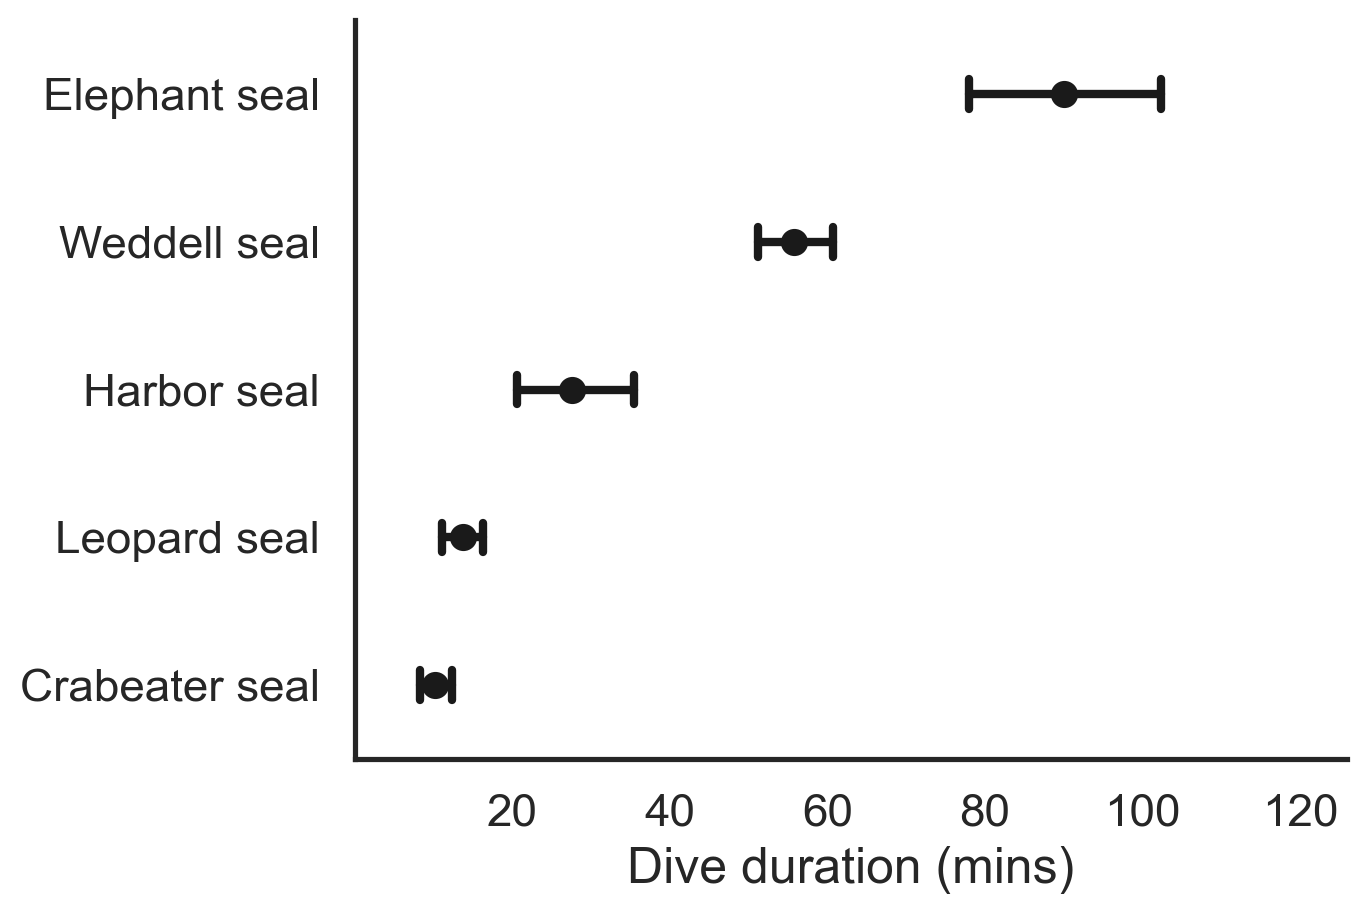

In [15]:
#| fig-align: center

ax = sns.pointplot(data=dives_cmp, y='group', x='dive_duration_min', capsize=.2, color="k", linestyle="none", marker="o", linewidth=3)
ax.set_xlim(*xlims)
ax.set_xlabel('Dive duration (mins)');
ax.set_ylabel('');

### Include the data

If there are not too many data including them can be useful to see the distribution of the data 

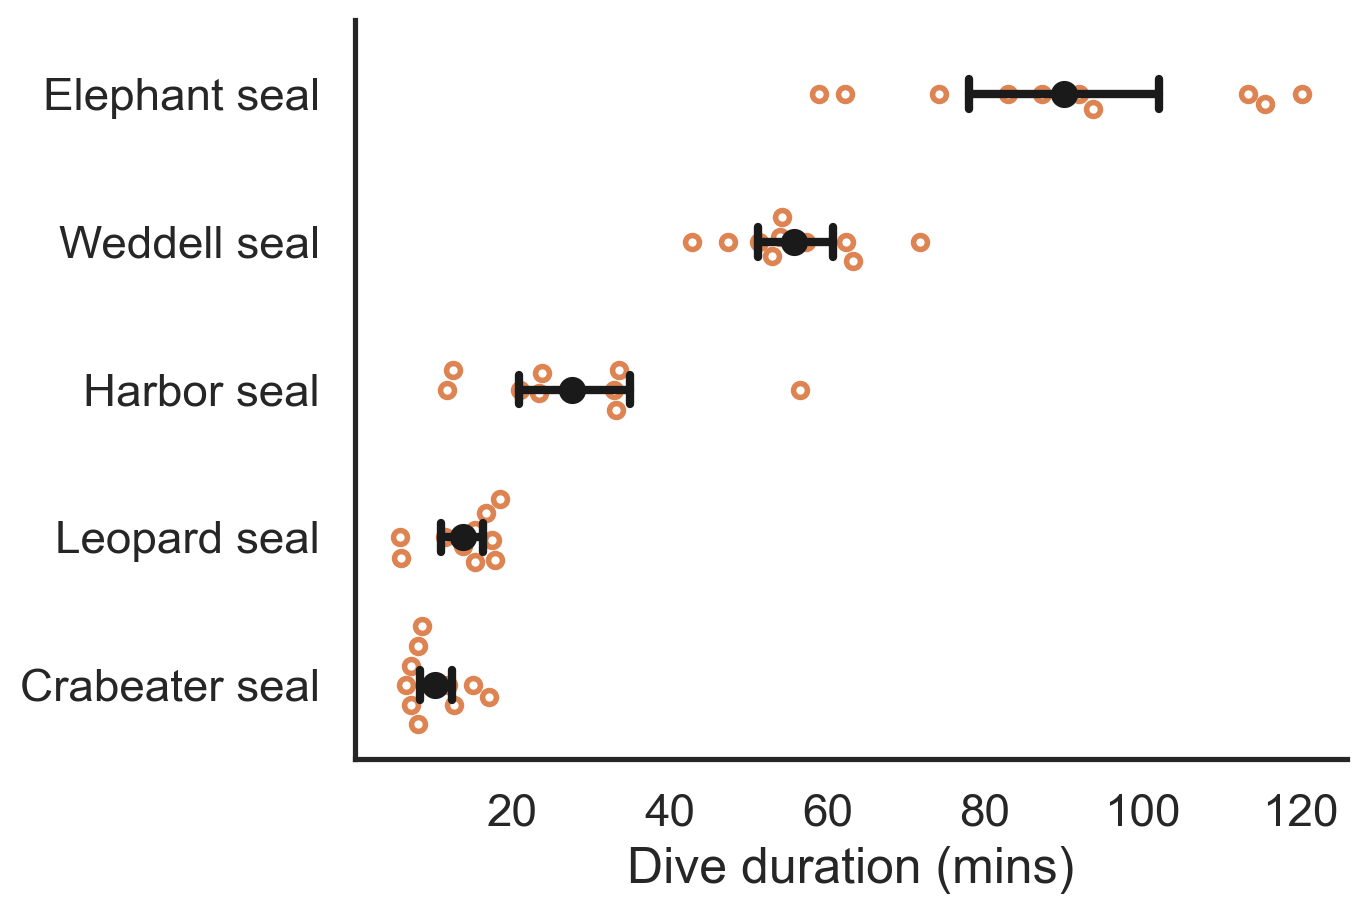

In [16]:
#| fig-align: center

ax = sns.pointplot(data=dives_cmp, y='group', x='dive_duration_min', capsize=.2, color="k", linestyle="none", marker="o", linewidth=3)
sns.swarmplot(data=dives_cmp, y='group', x='dive_duration_min', marker='o', zorder=0, facecolor='w', edgecolor='C1', linewidth=2)
ax.set_xlim(*xlims)
ax.set_xlabel('Dive duration (mins)')
ax.set_ylabel('');

### Always state what your error bars represent

::: {.callout-important}
Always state in the figure caption what errorbars represent (SEM, 95% CI) so that readers know how to interpret them.
:::

### Conclusion

Whenever we estimate a population parameter we must always include the uncertainty in that estimate.

### This week's class notebook

Three questions:

1. **Weddell seal dive durations**: 
    
    - The same analysis as in the lecture but with a larger data set

2. **Evolution of ground finch beak depths**:
    
    - Estimate the **difference** in the means of two populations
    - This is a little more complicated and is a prelude to Friday's material

3. **Proportion of hospital patients with vancomycin-resistant intestinal *Enterococcus* bacteria**
    
    - How to estimate a population proportion from a sample of data
    - Method 1: By using a formula for the standard error of the proportion
    - Method 2: By using Monte-Carlo simulation of the sampling distribution of a proportion
